# Laboratorio de Recomendación — del carrusel "Para ti" a la decisión

Cierra el bloque de Venta Cruzada y Recomendación (la palanca del ARPU). Van a trabajar con una
base **completa**: 8,000 clientes de una cadena de cafeterías, ~10 meses de historial de compras y
un **experimento de 90 días**: a la mitad de los clientes, elegida al azar, la app les mostró un
carrusel **"Para ti"** con los 3 productos más populares que aún no habían comprado. La otra mitad
(control) no vio ningún carrusel.

Este laboratorio repite, sobre la base completa, lo que practicaron en los Breakout Rooms:

| Dónde lo vieron | Qué van a repetir aquí |
|---|---|
| Breakout 2 — La matriz y el coseno | La matriz cliente × producto y la similitud de coseno |
| Breakout 3 — Filtrado por ítem y por cliente | Los dos recomendadores colaborativos (el puntaje es una suma de similitudes) |
| Breakout 4 — Comparar y medir | Hit rate@3, precisión@3 y cobertura con un holdout |

**Los 5 pasos del laboratorio:**
1. Construyen los recomendadores (popularidad, por ítem, por cliente y **uno propio**).
2. Los evalúan con el holdout, **solo en el grupo control** (sin contaminación del carrusel).
3. Miden el **efecto real** del carrusel con el experimento: ΔARPU, margen neto y ΔCLV.
4. Deciden qué recomendador llevarían al siguiente experimento, cuidando a los clientes sin historial.
5. **La revelación**: el dataset trae información oculta (qué compras *ya iban a ocurrir* y cuáles las *causó* el carrusel) que en la vida real nunca existe. La destapan al final y comparan.

Donde dice **`# TODO`** hay algo para que ustedes completen.

> Los efectos de este conjunto de datos están **plantados** por el generador. Sirven para practicar el método;
> no prueban que ninguna cadena real obtenga estos resultados.

In [ ]:
import os
REPO = "marketing-analytics-base-2026"
if not os.path.exists("data"):                      # si ya estamos dentro de Semana_4/Tarea no se vuelve a clonar
    if not os.path.exists(REPO):
        !git clone https://github.com/marioocanel-tech/marketing-analytics-base-2026.git
    %cd {REPO}/Semana_4/Tarea
!ls data

In [32]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

warnings.filterwarnings("ignore")
VERDE, OSCURO, NARANJA, GRIS = "#00704A", "#11241C", "#C4512F", "#9A988E"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

catalogo = pd.read_csv("data/catalogo.csv")
hist = pd.read_csv("data/ordenes_historial.csv", parse_dates=["order_date"])
hold = pd.read_csv("data/ordenes_holdout.csv", parse_dates=["order_date"])
exp = pd.read_csv("data/experimento.csv")
clientes = pd.read_csv("data/clientes.csv")

print(f"{len(clientes):,} clientes · {len(hist):,} líneas de historial ({hist['order_date'].min().date()} a {hist['order_date'].max().date()})")
print(f"Experimento: {hold['order_date'].min().date()} a {hold['order_date'].max().date()} · "
      f"{(exp['grupo'] == 'tratamiento').sum():,} tratamiento · {(exp['grupo'] == 'control').sum():,} control")
exp.head()

8,000 clientes · 71,523 líneas de historial (2025-09-01 a 2026-06-30)
Experimento: 2026-07-01 a 2026-09-28 · 4,000 tratamiento · 4,000 control


,customer_id,grupo,mostrados
0,1,control,NaN
1,2,tratamiento,Chocolate Caliente|Té Chai|Galleta
2,3,tratamiento,Chocolate Caliente|Té Chai|Galleta
3,4,tratamiento,Chocolate Caliente|Té Chai|Té Verde
4,5,tratamiento,Chocolate Caliente|Té Chai|Galleta


## Paso 1 — construyan los recomendadores

Todos producen una matriz de **puntajes**: una fila por cliente, una columna por producto.
Nada de lo que pasó en el experimento se puede usar para construirlos: **solo el historial**.

Primero la matriz cliente × producto (la misma del Breakout 2).

In [33]:
productos = list(catalogo["item"])
col_agua = productos.index("Agua")

# TODO 1: la matriz cliente × producto (1 si compró al menos una vez en el historial, 0 si no).
# Pista: pd.crosstab(...) > 0, y .reindex(...) para que estén los 8,000 clientes y los 29 productos,
#        en el orden de `clientes` y de `productos`.
M = (pd.crosstab(hist["customer_id"], hist["item"]) > 0).astype(int)
M = M.reindex(index=clientes["customer_id"], columns=productos, fill_value=0)

X = M.values.astype(np.float32)
print(f"Matriz {X.shape[0]:,} × {X.shape[1]} · densidad {X.mean():.1%} · clientes sin historial: {(X.sum(axis=1) == 0).sum()}")

Matriz 8,000 × 29 · densidad 14.6% · clientes sin historial: 334


Dos piezas que ya vienen armadas: la **popularidad** (a todos lo mismo, lo más comprado) y la función `top_k`,
que se queda con los K productos de mayor puntaje **que el cliente aún no compró** (y sin Agua).

In [34]:
# Respaldo: popularidad (a todos lo mismo, lo más comprado)
S_pop = np.tile(X.sum(axis=0), (len(X), 1))

def top_k(scores, K=3):
    s = np.where(X > 0, -np.inf, scores).astype(np.float64)   # no recomendar lo ya comprado
    s[:, col_agua] = -np.inf                                   # ni el Agua
    return np.argsort(-s, axis=1)[:, :K]

**Filtrado por ítem** (Breakout 3): se compara **producto con producto** (las columnas de `X`), se calcula la
tabla de similitudes **una sola vez**, y el puntaje de cada cliente es la **suma de las similitudes** de cada
candidato con lo que el cliente ya compró.

In [35]:
# TODO 2: filtrado por ítem
S_it = cosine_similarity(X.T)     # productos × productos
np.fill_diagonal(S_it, 0)
S_item = X @ S_it                 # clientes × productos
print(S_it.shape, S_item.shape)

(29, 29) (8000, 29)


**Filtrado por cliente** (Breakout 3): se compara **cliente con cliente** (las filas de `X`). Para cada cliente se
buscan sus **K vecinos más parecidos** y el puntaje de cada producto es la suma de las similitudes de los vecinos
que **sí lo compraron** (cada vecino vota con su similitud).

In [36]:
K_VECINOS = 30
S_us = cosine_similarity(X)                   # (clientes × clientes)
np.fill_diagonal(S_us, 0)

S_user = np.zeros_like(X)
for i in range(len(X)):
    # TODO 3: los K vecinos más parecidos del cliente i, y sus compras ponderadas por la similitud
    vec = np.argsort(-S_us[i])[:K_VECINOS]   # posiciones de los 30 clientes más parecidos
    S_user[i] = S_us[i, vec] @ X[vec]        # cada vecino vota con su similitud
print(S_us.shape, S_user.shape)

(8000, 8000) (8000, 29)


**Su propio recomendador.** El cuarto método lo eligen ustedes. Algunas ideas:
- **(a)** factorización con `TruncatedSVD(n_components=k)`: `Z = svd.fit_transform(X)` y `S_libre = Z @ svd.components_`
  (cada cliente y cada producto se resumen en unos pocos números "escondidos" de gusto);
- **(b)** el filtrado por cliente con otro K (10, 100, 300…);
- **(c)** un híbrido: mezcla de popularidad normalizada y filtrado por ítem;
- **(d)** cualquier otra idea suya (justifíquenla).

In [37]:
# TODO 4: SU modelo. Construyan una matriz de puntajes S_libre con la misma forma que X (8,000 × 29).
nombre_libre = "SVD (8 factores)"
svd = TruncatedSVD(n_components=8, random_state=42)
Z = svd.fit_transform(X)
S_libre = Z @ svd.components_

assert isinstance(S_libre, np.ndarray) and S_libre.shape == X.shape, "Completen el TODO 4: S_libre debe tener la misma forma que X"
metodos = {"Popularidad": S_pop, "Filtrado por ítem": S_item, "Filtrado por cliente": S_user, nombre_libre: S_libre}
print("Métodos listos:", list(metodos))

Métodos listos: ['Popularidad', 'Filtrado por ítem', 'Filtrado por cliente', 'SVD (8 factores)']


## Paso 2 — evalúen con el holdout, pero SOLO en el grupo control

- **Entrenamiento** = el historial (de ahí salieron las matrices).
- **Holdout** = los 90 días del experimento. De ahí sale la respuesta: qué productos **nuevos** (que el cliente nunca
  había comprado) probó cada cliente.

**Regla del laboratorio:** el hit rate se mide **solo en el grupo control**. En los tratados, el carrusel influyó en lo
que compraron y ya no es una compra "limpia". En el control, un acierto es una compra que **ocurrió sin ninguna recomendación**.

In [38]:
H = (pd.crosstab(hold["customer_id"], hold["item"]) > 0).astype(int).reindex(index=M.index, columns=productos, fill_value=0).values
NUEVO = H * (1 - X); NUEVO[:, col_agua] = 0              # lo que probó en el holdout y NO había comprado antes (sin Agua)
elegibles = NUEVO.sum(axis=1) > 0
es_control = (exp.set_index("customer_id").loc[M.index, "grupo"] == "control").values

print(f"Clientes que probaron algo NUEVO en los 90 días:")
print(f"  control      : {(elegibles & es_control).sum():,} de {es_control.sum():,} ({elegibles[es_control].mean():.0%})")
print(f"  tratamiento  : {(elegibles & ~es_control).sum():,} de {(~es_control).sum():,} ({elegibles[~es_control].mean():.0%})")

Clientes que probaron algo NUEVO en los 90 días:
  control      : 1,797 de 4,000 (45%)
  tratamiento  : 2,297 de 4,000 (57%)


In [39]:
def hit_rate_at_k(scores, K=3, mask=None):
    top = top_k(scores, K)
    # TODO 5: ¿al menos una de las K recomendaciones fue un producto NUEVO que el cliente compró? (True/False por cliente)
    # Pista: NUEVO[u, top[u]] son los 1/0 de los K productos recomendados al cliente u.
    aciertos = np.array([NUEVO[u, top[u]].sum() > 0 for u in range(len(top))])
    return aciertos[mask].mean()

def precision_at_k(scores, K=3, mask=None):
    top = top_k(scores, K)
    return np.mean([NUEVO[u, top[u]].sum() / K for u in np.where(mask)[0]])

def cobertura(scores, K=3):
    return len(np.unique(top_k(scores, K)))

mask_eval = es_control & elegibles
res = pd.DataFrame({n: {"hit rate@3": hit_rate_at_k(s, mask=mask_eval),
                        "precisión@3": precision_at_k(s, mask=mask_eval),
                        "cobertura (de 28)": cobertura(s)} for n, s in metodos.items()}).T
res.round(3)

,hit rate@3,precisión@3,cobertura (de 28)
Popularidad,0.221,0.078,12.0
Filtrado por ítem,0.401,0.144,28.0
Filtrado por cliente,0.299,0.109,28.0
SVD (8 factores),0.369,0.132,28.0


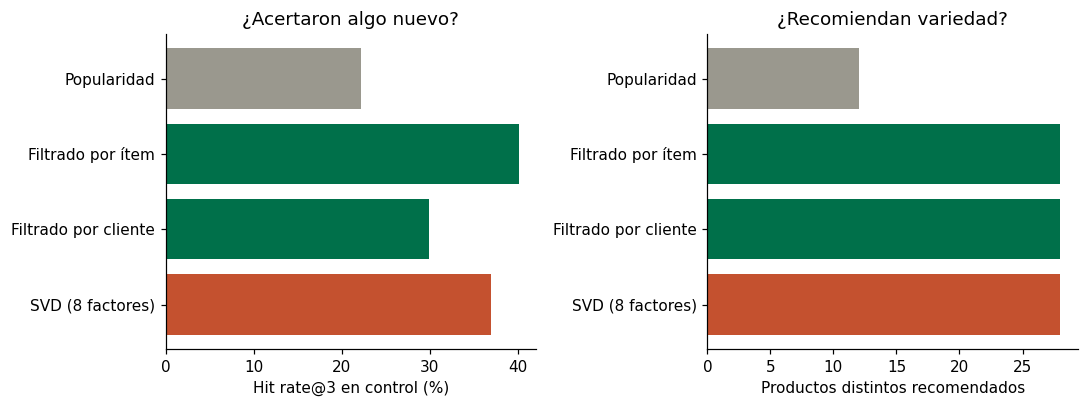

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
colores = [GRIS, VERDE, VERDE, NARANJA]
ax[0].barh(res.index[::-1], res["hit rate@3"][::-1] * 100, color=colores[::-1]); ax[0].set_xlabel("Hit rate@3 en control (%)"); ax[0].set_title("¿Acertaron algo nuevo?")
ax[1].barh(res.index[::-1], res["cobertura (de 28)"][::-1], color=colores[::-1]); ax[1].set_xlabel("Productos distintos recomendados"); ax[1].set_title("¿Recomiendan variedad?")
plt.tight_layout(); plt.show()

**Respondan aquí (2–3 líneas cada una):**
1. ¿Por qué evaluamos **solo en el grupo control**? ¿Qué pasaría con el hit rate si usáramos también a los tratados?
2. ¿Qué significa un "acierto" en el grupo control? ¿Fue *causado* por el recomendador?
3. ¿Qué método ganó y por cuánto sobre la popularidad? ¿Y en cobertura?

### Respuestas — Paso 2

**1. ¿Por qué evaluamos solo en el grupo control?** Porque el grupo control **no vio el carrusel**: lo que compró es lo que habría comprado por su cuenta, así que el hit rate mide si el recomendador *predice* ese comportamiento sin contaminación. Los tratados vieron los 3 productos más populares, y eso por sí solo cambia lo que compran: en el notebook, el 57% de los tratados probó algo nuevo contra 45% en control. Incluirlos inflaría el hit rate (sobre todo el de popularidad, porque el carrusel mostró justo esos productos) y mezclaría "adivinar" con "empujar".

**2. ¿Qué significa un acierto en control? ¿Lo causó el recomendador?** Significa que al menos uno de los 3 productos recomendados es un producto **nuevo que ese cliente terminó comprando** en los 90 días. **No** fue causado por el recomendador: en control nadie vio la recomendación, así que el acierto solo dice que el modelo predice bien lo que el cliente ya iba a hacer. Acierto ≠ causa; para saber cuánto vende *de más* hace falta un experimento.

**3. ¿Qué método ganó y por cuánto?** Entre los cuatro métodos de este paso, el **filtrado por ítem** tuvo el mejor hit rate@3: **40.1% vs 22.1% de popularidad** (+18 puntos, ≈ ×1.8). Le siguen SVD (36.9%) y filtrado por cliente (29.9%). En **cobertura** la diferencia es aún mayor: popularidad recomienda solo **12 de 28** productos (todos reciben lo mismo) y los tres métodos personalizados recomiendan **los 28**. (Más adelante, el recomendador Final —ítem + respaldo— sube a 41.0%.)

## Paso 3 — midan el efecto REAL del carrusel con el experimento

Aquí **sí** usan a los dos grupos. Como la asignación fue al azar, la diferencia entre tratamiento y control es el
efecto causal del carrusel (el que mostró los 3 productos más populares).

Primero el ingreso y el margen de cada cliente en los 90 días (con los precios y márgenes del catálogo).

In [41]:
precio = catalogo.set_index("item")["precio"]
margen = catalogo.set_index("item")["margen"]
hold["ingreso"] = hold["item"].map(precio)
hold["margen_usd"] = hold["ingreso"] * hold["item"].map(margen)
por_cliente = hold.groupby("customer_id")[["ingreso", "margen_usd"]].sum().reindex(clientes["customer_id"]).fillna(0)
ab = exp.set_index("customer_id").join(por_cliente)

trat = ab[ab["grupo"] == "tratamiento"]
ctrl = ab[ab["grupo"] == "control"]
print(f"ARPU de 90 días · control ${ctrl['ingreso'].mean():.2f} · tratamiento ${trat['ingreso'].mean():.2f}")
print(f"Un cliente de control gasta ${ctrl['ingreso'].mean():.2f} en promedio, con desviación estándar ${ctrl['ingreso'].std():.2f}")

ARPU de 90 días · control $15.74 · tratamiento $16.85
Un cliente de control gasta $15.74 en promedio, con desviación estándar $16.71


In [42]:
COSTO_CARRUSEL = 0.20   # US$ por cliente tratado en los 90 días (diseño, hosting y mantenimiento del carrusel)

# TODO 6: efecto del carrusel = diferencia de medias del ingreso (tratamiento − control) y su error estándar
#         error estándar = raíz( var_t / n_t + var_c / n_c );  IC 95% = diferencia ± 1.96 × error estándar
delta_arpu = trat["ingreso"].mean() - ctrl["ingreso"].mean()
ee_arpu = np.sqrt(trat["ingreso"].var() / len(trat) + ctrl["ingreso"].var() / len(ctrl))
ic_arpu = (delta_arpu - 1.96 * ee_arpu, delta_arpu + 1.96 * ee_arpu)

delta_margen = trat["margen_usd"].mean() - ctrl["margen_usd"].mean()
ee_margen = np.sqrt(trat["margen_usd"].var() / len(trat) + ctrl["margen_usd"].var() / len(ctrl))
delta_margen_neto = delta_margen - COSTO_CARRUSEL
ic_margen_neto = (delta_margen_neto - 1.96 * ee_margen, delta_margen_neto + 1.96 * ee_margen)

print(f"ΔARPU (ingreso):  ${delta_arpu:+.2f} por cliente · IC 95% {ic_arpu[0]:+.2f} a {ic_arpu[1]:+.2f}")
print(f"Δmargen neto (después del costo del carrusel): ${delta_margen_neto:+.2f} por cliente · IC 95% {ic_margen_neto[0]:+.2f} a {ic_margen_neto[1]:+.2f}")

ΔARPU (ingreso):  $+1.11 por cliente · IC 95% +0.37 a +1.86
Δmargen neto (después del costo del carrusel): $+0.51 por cliente · IC 95% +0.05 a +0.98


Ahora conecten el ARPU con la fórmula de CLV de la clase:

**CLV = ARPU × margen × r / (1 + d − r) − CAC**

El carrusel solo mueve el **ARPU** (la palanca de esta semana). Supuestos dados, **trimestrales**: retención `r = 0.78` y
tasa de descuento `d = 0.03`.

In [43]:
R_TRIM, D_TRIM = 0.78, 0.03    # retención y tasa de descuento por trimestre (supuestos dados)

# TODO 7: factor de vida esperada = r / (1 + d − r)   y   ΔCLV por cliente = Δmargen neto × factor
#         (supuesto: el efecto del carrusel se mantiene mientras el cliente siga activo)
factor_vida = R_TRIM / (1 + D_TRIM - R_TRIM)
delta_clv = delta_margen_neto * factor_vida

print(f"Factor de vida esperada: {factor_vida:.2f} trimestres · ΔCLV por cliente ≈ ${delta_clv:+.2f}")
print(f"Para los {len(trat):,} clientes con carrusel: ${delta_clv * len(trat):+,.0f}")

Factor de vida esperada: 3.12 trimestres · ΔCLV por cliente ≈ $+1.60
Para los 4,000 clientes con carrusel: $+6,406


**Respondan aquí (2–3 líneas cada una):**
1. ¿El efecto del carrusel es estadísticamente distinto de cero? ¿Qué tan ancho es el intervalo y por qué (miren la desviación estándar del gasto)?
2. ¿Vale la pena el carrusel? Comparen el Δmargen con su costo y con el ΔCLV.
3. ¿Qué supuesto del ΔCLV es el más frágil?

### Respuestas — Paso 3

**1. ¿Es estadísticamente distinto de cero?** Sí. ΔARPU = **+US$1.11** por cliente (ARPU control US$15.74 vs tratamiento US$16.85), con IC 95% de **+0.37 a +1.86**; el intervalo no incluye el cero (z ≈ 2.9). Pero es **ancho** (≈ US$1.49 de punta a punta): el gasto de cada cliente varía muchísimo (desviación estándar ≈ US$16.7, quince veces el efecto), y con 4,000 clientes por grupo el error estándar queda en ≈ US$0.38. Sabemos que el efecto es positivo, pero no cuánto con precisión.

**2. ¿Vale la pena?** Sí, con holgura estrecha. El Δmargen bruto es **US$0.71** por cliente, ≈ 3.6 veces el costo del carrusel (US$0.20); el **Δmargen neto es +US$0.51** (IC 95% +0.05 a +0.98: positivo, aunque el extremo inferior casi toca cero). Convertido a valor de vida, **ΔCLV ≈ +US$1.60 por cliente** (factor 3.12 trimestres), ≈ **US$6,406** para los 4,000 clientes con carrusel. Es rentable en promedio, pero el rango es amplio (ΔCLV de ≈ US$0.15 a US$3.05).

**3. ¿Qué supuesto del ΔCLV es el más frágil?** Que el efecto de US$0.51 por trimestre **se mantiene mientras el cliente siga activo** (y que la retención r = 0.78 no cambia). Lo medimos en solo 90 días, y un carrusel nuevo tiene efecto novedad: parte del salto puede desvanecerse. Como el ΔCLV multiplica el efecto por ≈ 3 trimestres, si el efecto decae el ΔCLV se desploma; además, el extremo inferior del intervalo (+0.05) ya está cerca de cero.

## Paso 4 — decidan qué llevarían al siguiente experimento

El carrusel del experimento mostró **popularidad**. Ustedes tienen mejores candidatos, pero **ninguno se probó con
un grupo de control**: solo tienen su hit rate en el grupo control (acierto ≠ causa). Primero revisen un problema
práctico: los clientes **sin historial** (arranque en frío).

In [44]:
n_prod = X.sum(axis=1)
tramos = pd.cut(n_prod, [-1, 0, 2, 5, 100], labels=["0 productos", "1–2", "3–5", "6+"])

filas = {}
for nombre in ["Popularidad", "Filtrado por ítem", "Filtrado por cliente"]:
    filas[nombre] = {t: hit_rate_at_k(metodos[nombre], mask=mask_eval & (tramos == t)) for t in tramos.categories}
tabla_frio = pd.DataFrame(filas).T
print("Clientes elegibles de control por tramo de historial:", {t: int((mask_eval & (tramos == t)).sum()) for t in tramos.categories})
tabla_frio.round(3)

Clientes elegibles de control por tramo de historial: {'0 productos': 98, '1–2': 285, '3–5': 790, '6+': 624}


,0 productos,1–2,3–5,6+
Popularidad,0.337,0.196,0.208,0.232
Filtrado por ítem,0.163,0.474,0.427,0.372
Filtrado por cliente,0.163,0.161,0.324,0.353


In [45]:
# TODO 8: recomendador FINAL = filtrado por ítem para quien tiene historial, y popularidad para quien no (arranque en frío)
tiene_historial = (X.sum(axis=1) > 0)[:, None]
S_final = np.where(tiene_historial, S_item, S_pop)

metodos["Final (ítem + respaldo)"] = S_final
print("hit rate@3 en control · ítem solo:", round(hit_rate_at_k(S_item, mask=mask_eval), 3),
      "· final (ítem + respaldo):", round(hit_rate_at_k(S_final, mask=mask_eval), 3))

hit rate@3 en control · ítem solo: 0.401 · final (ítem + respaldo): 0.41


**Respondan aquí (una decisión defendida con sus números):**
1. ¿Qué recomendador llevarían al siguiente experimento? Consideren hit rate, **cobertura**, costo de calcularlo, **explicabilidad**
   ("porque compraste X") y qué pasa con los clientes sin historial.
2. Diseñen en tres líneas el experimento para medir el **ARPU incremental** de ese recomendador: grupos, métrica, duración
   y cómo evitarían el sesgo de novedad.

### Respuestas — Paso 4

**1. Recomendador para el siguiente experimento: el Final (filtrado por ítem + popularidad como respaldo).**
- **Hit rate:** 41.0% en control, el más alto (ítem solo 40.1%, SVD 36.9%, cliente 29.9%, popularidad 22.1%).
- **Cobertura:** 28 de 28 productos (popularidad: 12), o sea, el carrusel sí personaliza.
- **Costo de cálculo:** una tabla de 29×29 productos que se calcula una vez; el filtrado por cliente exige comparar a los 8,000 clientes entre sí (8,000×8,000) y fue el peor de los personalizados.
- **Explicabilidad:** "porque compraste X, que suele comprarse junto con Y"; SVD ganaría casi tanto pero no se puede explicar en una frase.
- **Sin historial (arranque en frío):** el filtrado por ítem no tiene señal para quien no compró nada (hit rate 16.3% en el tramo "0 productos" vs 33.7% de popularidad). Con el respaldo, esos 334 clientes reciben lo más popular. La tabla muestra además que el ítem domina con historial corto (47% con 1–2 productos).

**2. Diseño del experimento (3 líneas).**
- **Grupos:** asignación aleatoria por cliente, estratificada por tramo de historial: control (sin carrusel) vs tratamiento (recomendador Final); idealmente un tercer grupo con popularidad para comparar recomendadores entre sí.
- **Métrica y tamaño:** ARPU y margen neto por cliente a 90 días (primaria), con IC; con desviación estándar ≈ US$17, detectar un efecto de ≈ US$1 exige ≈ 4,000–5,000 clientes por grupo, y detectar una diferencia de ≈ US$0.19 entre recomendadores exigiría > 100,000 por grupo.
- **Sesgo de novedad:** medir ≥ 90 días (idealmente 2–3 ciclos de compra), comparar la tendencia semana a semana (primeras 4 vs últimas 4) y mantener un grupo control permanente para ver si el efecto decae.

## La revelación final

Esta es la parte que no pudieron hacer con datos reales: los archivos `verdad_oculta_cliente_producto.csv` y
`verdad_oculta_clientes.csv` traen, para cada cliente y producto que aún no compró:

- `p_organica`: la probabilidad de que lo comprara **por cuenta propia** en los 90 días (sin ninguna recomendación);
- `p_incremental`: cuánto **sube** esa probabilidad **si se le muestra** en el carrusel.

En la vida real nadie conoce estas columnas. Compárenlas contra lo que midieron.

In [46]:
vo_cp = pd.read_csv("data/verdad_oculta_cliente_producto.csv")
vo_cl = pd.read_csv("data/verdad_oculta_clientes.csv").set_index("customer_id").loc[M.index]
pi = vo_cp.pivot(index="customer_id", columns="item", values="p_incremental").reindex(index=M.index, columns=productos).fillna(0).values
po = vo_cp.pivot(index="customer_id", columns="item", values="p_organica").reindex(index=M.index, columns=productos).fillna(0).values
precio_v = catalogo.set_index("item")["precio"].reindex(productos).values
n = len(X); filas_ = np.arange(n)[:, None]

filas = {}
for nombre, S in metodos.items():
    tk = top_k(S)
    inc = pi[filas_, tk].sum(axis=1)                       # compras EXTRA esperadas si se le muestran esos 3 productos
    inc_usd = (pi[filas_, tk] * precio_v[tk]).sum(axis=1)
    org = po[filas_, tk].sum(axis=1)                       # compras de esos 3 que YA iban a ocurrir
    filas[nombre] = {"hit rate@3 (control)": hit_rate_at_k(S, mask=mask_eval),
                     "ingreso incremental esperado (US$/cliente)": inc_usd.mean(),
                     "% de las compras que ya iban a ocurrir": org.sum() / (org.sum() + inc.sum())}
rev = pd.DataFrame(filas).T
rev.round(3)

,hit rate@3 (control),ingreso incremental esperado (US$/cliente),% de las compras que ya iban a ocurrir
Popularidad,0.221,0.998,0.307
Filtrado por ítem,0.401,1.191,0.438
Filtrado por cliente,0.299,1.186,0.376
SVD (8 factores),0.369,1.213,0.411
Final (ítem + respaldo),0.410,1.181,0.443


Efecto VERDADERO del carrusel (ingreso por cliente tratado): $0.99
Lo que midió su experimento (Paso 3): $+1.11 · IC 95% +0.37 a +1.86  →  ¿cae dentro?  True


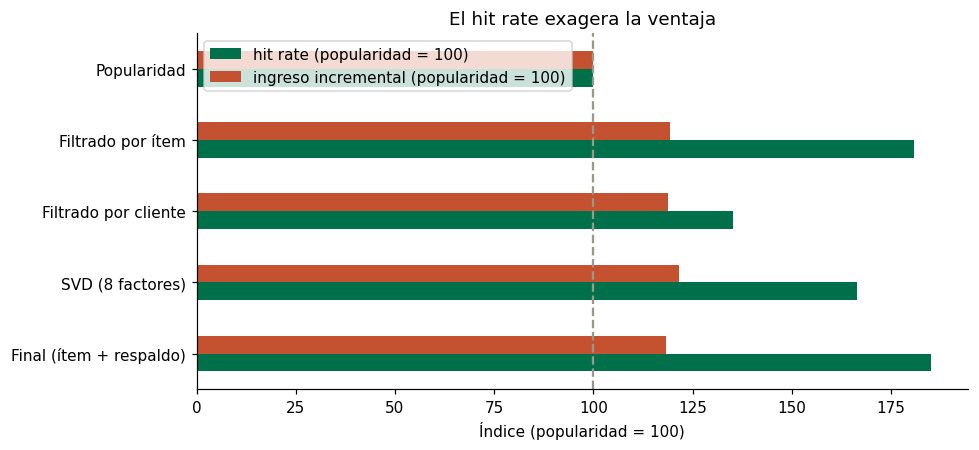

In [47]:
tk_pop = top_k(S_pop)
real_trat = (pi[filas_, tk_pop] * precio_v[tk_pop]).sum(axis=1)[~es_control].mean()
print(f"Efecto VERDADERO del carrusel (ingreso por cliente tratado): ${real_trat:.2f}")
print(f"Lo que midió su experimento (Paso 3): ${delta_arpu:+.2f} · IC 95% {ic_arpu[0]:+.2f} a {ic_arpu[1]:+.2f}  →  ¿cae dentro?  {ic_arpu[0] <= real_trat <= ic_arpu[1]}")

idx = pd.DataFrame({
    "hit rate (popularidad = 100)": rev["hit rate@3 (control)"] / rev.loc["Popularidad", "hit rate@3 (control)"] * 100,
    "ingreso incremental (popularidad = 100)": rev["ingreso incremental esperado (US$/cliente)"] / rev.loc["Popularidad", "ingreso incremental esperado (US$/cliente)"] * 100,
})
ax = idx.iloc[::-1].plot.barh(color=[VERDE, NARANJA], figsize=(9, 4.2))
ax.axvline(100, color=GRIS, linestyle="--"); ax.set_xlabel("Índice (popularidad = 100)"); ax.set_title("El hit rate exagera la ventaja")
plt.tight_layout(); plt.show()

In [48]:
# ¿A todos hay que mostrarles el carrusel? El efecto depende de qué tan receptivo es cada cliente (columna oculta)
cuartil = pd.qcut(vo_cl["receptividad"], 4, labels=["Q1 (menos receptivos)", "Q2", "Q3", "Q4 (más receptivos)"])
tk = top_k(S_item)
inc_usd_item = (pi[filas_, tk] * precio_v[tk]).sum(axis=1)
pd.Series(inc_usd_item).groupby(cuartil.values).mean().round(2).rename("ingreso incremental esperado (US$/cliente) · filtrado por ítem")

,ingreso incremental esperado (US$/cliente) · filtrado por ítem
Q1 (menos receptivos),0.47
Q2,0.94
Q3,1.38
Q4 (más receptivos),1.98


**Respondan aquí (2–3 líneas cada una):**
1. ¿Cae el efecto verdadero dentro del intervalo que midió su experimento?
2. Comparen el **hit rate** con el **ingreso incremental** de cada método. ¿La ventaja del filtrado por ítem sobre la popularidad es igual de grande en las dos medidas? ¿Por qué?
3. ¿Qué porcentaje de las compras "acertadas" **ya iban a ocurrir**? ¿Qué significa para el ARPU que reportaría un directivo si solo mirara el hit rate?
4. Según los cuartiles de receptividad: ¿a todos los clientes hay que mostrarles el carrusel? ¿Qué técnica de la Semana 3 ayudaría a decidir a quién?

### Respuestas — La revelación final

**1. ¿Cae el efecto verdadero dentro del intervalo?** Sí. El efecto verdadero del carrusel de popularidad es **US$0.99** por cliente tratado; el experimento midió **+US$1.11** con IC 95% de +0.37 a +1.86, y 0.99 cae dentro. El experimento acertó en el orden de magnitud, pero con un intervalo muy ancho.

**2. Hit rate vs ingreso incremental.** No, la ventaja no es igual. El filtrado por ítem multiplica por **×1.81** el hit rate de popularidad (+81%: 40.1% vs 22.1%) pero solo por **×1.19** el ingreso incremental (US$1.191 vs US$0.998: +19%). El Final pasa de ×1.85 en hit rate a ×1.18 en ingreso. Y el mejor en ingreso incremental es **SVD (US$1.213)**, no el de mejor hit rate. El hit rate premia **acertar lo que el cliente ya iba a comprar** (la compra orgánica) y no pesa cuánto cambia la decisión el mostrarle el producto; por eso exagera el valor de los métodos que mejor predicen.

**3. ¿Qué porcentaje de las compras acertadas ya iba a ocurrir?** Entre **31%** (popularidad) y **44%** (filtrado por ítem 43.8%; Final 44.3%); filtrado por cliente 37.6% y SVD 41.1%. Cuanto mejor "adivina" el método, mayor es la parte que habría ocurrido igual. Si un directivo viera solo el hit rate y lo leyera como ARPU extra, **sobreestimaría** el ingreso que genera el carrusel: casi la mitad de esas compras no son extra, y el ingreso incremental sube mucho menos que el hit rate.

**4. Cuartiles de receptividad.** No a todos. Con el filtrado por ítem, el ingreso incremental pasa de **US$0.47** (Q1, menos receptivos) a **US$1.98** (Q4), cuatro veces más. Con margen de ≈ 60% y el costo de US$0.20 por cliente, el Q1 queda **casi en el punto de equilibrio** (margen neto de ≈ US$0.06–0.08), mientras que Q3 y Q4 dejan US$0.55–0.97. Conviene **focalizar**: un modelo de **uplift** (estimar el efecto incremental por cliente comparando tratamiento y control) para decidir a quién mostrarle el carrusel, en vez de mostrárselo a toda la base.

## Tabla resumen de recomendadores

| Recomendador | Hit rate@3 (control) | Ingreso incremental (US$/cliente, 90 días) | % de compras acertadas que ya iban a ocurrir | Cobertura (de 28) |
|---|---|---|---|---|
| Popularidad | 22.1% | 0.998 | 30.7% | 12 |
| Filtrado por ítem | 40.1% | 1.191 | 43.8% | 28 |
| Filtrado por cliente (K=30) | 29.9% | 1.186 | 37.6% | 28 |
| SVD (8 factores) | 36.9% | 1.213 | 41.1% | 28 |
| **Final (ítem + respaldo popularidad)** | **41.0%** | 1.181 | 44.3% | 28 |

**Lectura:** el hit rate separa mucho a los métodos (de 22% a 41%); el ingreso incremental, no (de US$1.00 a US$1.21). Un hit rate alto no equivale a ingreso extra. Las diferencias entre los métodos personalizados (≈ US$1.18–1.21) son menores que el ruido que podría medir un experimento de este tamaño.

## Para entregar

1. El notebook completo, **ejecutado de principio a fin**, con sus respuestas a las preguntas de cada paso.
2. **Su propia app de Streamlit** (usen `streamlit_starter.py` como punto de partida) que le permita a alguien de
   negocio explorar los recomendadores: elegir un cliente y un método, ver sus **3 recomendaciones con el "porque"**, y la
   tabla de comparación (hit rate y cobertura) — con al menos un control interactivo (slider o selector).
3. Una conclusión de una página para el Presidente de Marketing: ¿qué recomendador llevarían al siguiente experimento,
   cuánto vale (ΔARPU y ΔCLV) y qué tan cerca estuvo el hit rate de la verdad?